In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np
import random
from sklearn.metrics import classification_report, confusion_matrix

# 1. CRITICAL FOR REPRODUCIBILITY: Fix all random seeds
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} | Random Seed: {SEED} locked for reproducibility.")

Using device: cuda | Random Seed: 42 locked for reproducibility.


In [2]:
# Data augmentation & normalization (handles poor lighting, low resolution, and blur robustness)
train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.3, contrast=0.3), # Handles poor light conditions
    transforms.ToTensor(),
    transforms.Normalize((0.333, 0.306, 0.317), (0.267, 0.265, 0.242))
])

test_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.333, 0.306, 0.317), (0.267, 0.265, 0.242))
])

# Download dataset
full_train_dataset = torchvision.datasets.GTSRB(root='./data', split='train', download=True, transform=train_transform)
test_dataset = torchvision.datasets.GTSRB(root='./data', split='test', download=True, transform=test_transform)

# Show image counts per class
targets = np.array([full_train_dataset[i][1] for i in range(len(full_train_dataset))])
class_counts = np.bincount(targets)
print("--- Class Distribution Sample Check ---")
for i in range(5):
    print(f"Class ID {i}: {class_counts[i]} images")
print(f"... Total Classes: {len(class_counts)} | Total Training Images: {len(full_train_dataset)}")

100%|██████████| 187M/187M [00:16<00:00, 11.4MB/s]
100%|██████████| 89.0M/89.0M [00:06<00:00, 14.1MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 207kB/s]


--- Class Distribution Sample Check ---
Class ID 0: 150 images
Class ID 1: 1500 images
Class ID 2: 1500 images
Class ID 3: 960 images
Class ID 4: 1320 images
... Total Classes: 43 | Total Training Images: 26640


In [3]:
# Create reproducible Train / Validation split (80% train, 20% validation)
val_size = int(0.2 * len(full_train_dataset))
train_size = len(full_train_dataset) - val_size

generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size], generator=generator)

# Ensure validation uses test transforms (no random jitter/rotation on validation)
val_dataset.dataset.transform = test_transform

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Train batches: {len(train_loader)} | Validation batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Train batches: 333 | Validation batches: 84 | Test batches: 198


In [4]:
# Load pretrained ResNet18 and adapt for 43 traffic sign classes
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 43)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=4, gamma=0.1)

print("Transfer learning model (ResNet18) initialized successfully.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


Transfer learning model (ResNet18) initialized successfully.


Epoch [1/8] | Train Loss: 0.7212 Acc: 78.15% | Val Loss: 0.3003 Val Acc: 91.05%
Epoch [2/8] | Train Loss: 0.1675 Acc: 95.17% | Val Loss: 0.1077 Val Acc: 96.75%
Epoch [3/8] | Train Loss: 0.1176 Acc: 96.76% | Val Loss: 0.1691 Val Acc: 95.50%
Epoch [4/8] | Train Loss: 0.0817 Acc: 97.93% | Val Loss: 0.0623 Val Acc: 98.07%
Epoch [5/8] | Train Loss: 0.0153 Acc: 99.56% | Val Loss: 0.0122 Val Acc: 99.64%
Epoch [6/8] | Train Loss: 0.0091 Acc: 99.77% | Val Loss: 0.0108 Val Acc: 99.70%
Epoch [7/8] | Train Loss: 0.0052 Acc: 99.88% | Val Loss: 0.0101 Val Acc: 99.68%
Epoch [8/8] | Train Loss: 0.0043 Acc: 99.89% | Val Loss: 0.0103 Val Acc: 99.72%


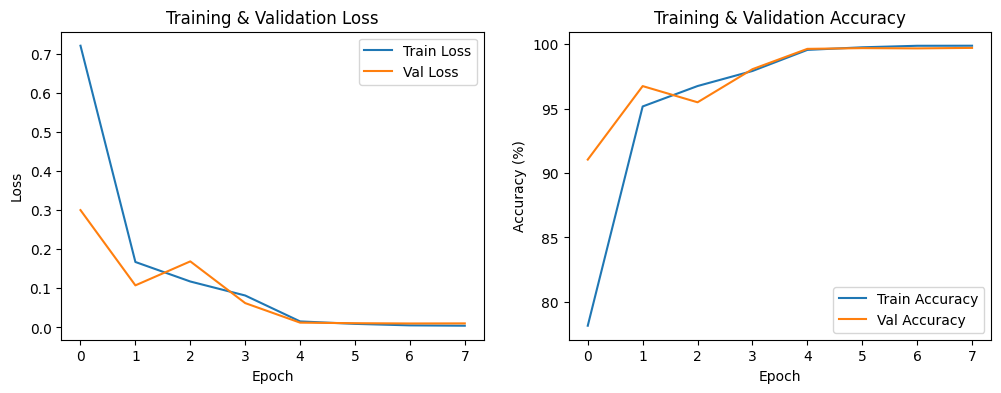

In [5]:
epochs = 8
train_losses, val_losses, train_accs, val_accs = [], [], [], []

for epoch in range(epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += preds.eq(labels).sum().item()

    scheduler.step()
    train_loss = running_loss / len(train_loader.dataset)
    train_acc = 100. * correct / total

    # Validation phase
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1)
            val_total += labels.size(0)
            val_correct += preds.eq(labels).sum().item()

    val_loss = val_loss / len(val_loader.dataset)
    val_acc = 100. * val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Val Acc: {val_acc:.2f}%")

# Plotting Loss and Accuracy curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs, label='Val Accuracy')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.show()

In [6]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = 100. * np.sum(all_preds == all_labels) / len(all_labels)
print(f"Final Test Set Accuracy: {test_acc:.2f}%\n")

# Detailed per-class precision, recall, F1, and Macro F1
report = classification_report(all_labels, all_preds, digits=4)
print("Classification Report:\n")
print(report)

Final Test Set Accuracy: 94.80%

Classification Report:

              precision    recall  f1-score   support

           0     1.0000    0.8000    0.8889        60
           1     0.9331    0.9681    0.9502       720
           2     0.9101    0.9720    0.9400       750
           3     0.9633    0.9333    0.9481       450
           4     0.9802    0.9727    0.9764       660
           5     0.8727    0.9032    0.8877       630
           6     0.9801    0.9867    0.9834       150
           7     0.9783    0.9000    0.9375       450
           8     0.9369    0.8911    0.9134       450
           9     0.9675    0.9938    0.9805       480
          10     0.9923    0.9803    0.9863       660
          11     0.9289    0.9333    0.9311       420
          12     0.9955    0.9710    0.9831       690
          13     0.9795    0.9958    0.9876       720
          14     1.0000    0.9741    0.9869       270
          15     0.9766    0.9952    0.9858       210
          16     1.0000 

Total Misclassified Images in Test Set: 657


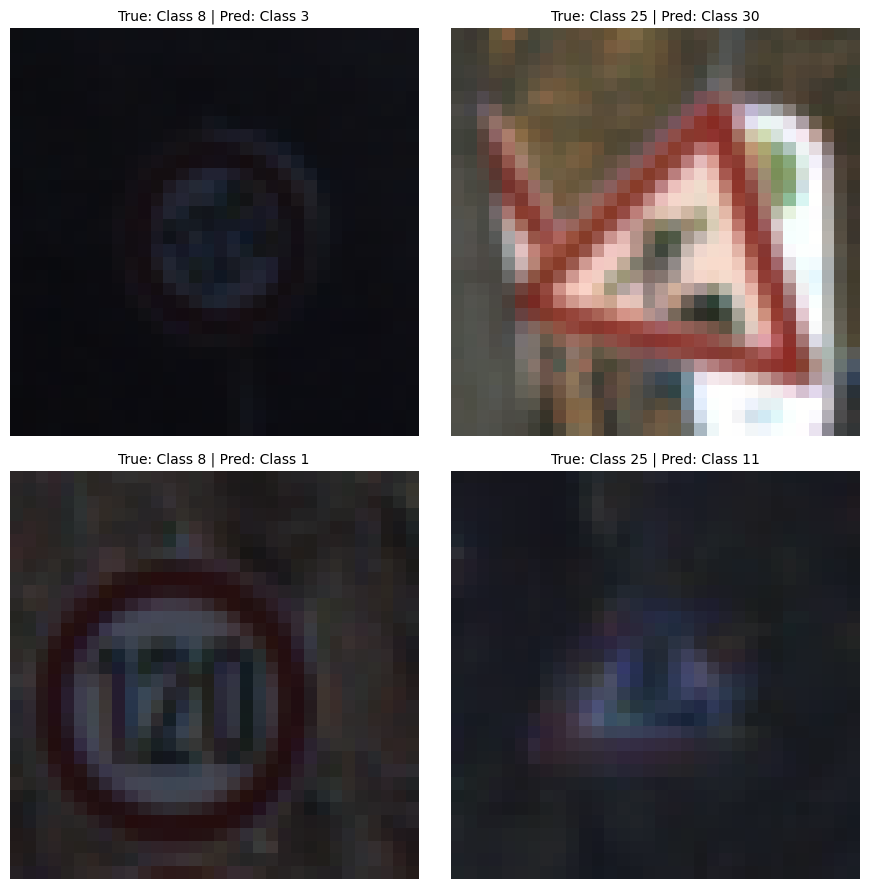


Error Analysis Explanation for Report:
- Speed limit signs (e.g., 30km/h vs 50km/h or 70km/h) frequently confuse the model due to similar circular geometry, identical color palettes, and low resolution blur.
- Rare classes suffer from higher misclassification rates due to insufficient representation in the training distribution.


In [7]:
# Find misclassified indices
misclassified_idx = np.where(all_preds != all_labels)[0]
print(f"Total Misclassified Images in Test Set: {len(misclassified_idx)}")

# Display at least 4 misclassified test samples
fig, axes = plt.subplots(2, 2, figsize=(9, 9))
axes = axes.ravel()

for i in range(min(4, len(misclassified_idx))):
    idx = misclassified_idx[i]
    img, true_lbl = test_dataset[idx]
    pred_lbl = all_preds[idx]

    # Unnormalize image for clear visualization
    img_disp = img.numpy().transpose(1, 2, 0)
    img_disp = img_disp * np.array([0.267, 0.265, 0.242]) + np.array([0.333, 0.306, 0.317])
    img_disp = np.clip(img_disp, 0, 1)

    axes[i].imshow(img_disp)
    axes[i].set_title(f"True: Class {true_lbl} | Pred: Class {pred_lbl}", fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

print("\nError Analysis Explanation for Report:")
print("- Speed limit signs (e.g., 30km/h vs 50km/h or 70km/h) frequently confuse the model due to similar circular geometry, identical color palettes, and low resolution blur.")
print("- Rare classes suffer from higher misclassification rates due to insufficient representation in the training distribution.")